In [3]:
import time
import sys
import os

# Add the parent directory to sys.path
notebook_path = os.getcwd()  # Get the current working directory where the notebook is located
parent_directory = os.path.dirname(notebook_path)  # Move to the parent directory
sys.path.append(parent_directory)

# Now you can import config
from config import *
#from Minimal_Model_2D import *
#import Minimal_Model_2D as mm2d
import time

np.set_printoptions(threshold=sys.maxsize)

import Minimal_Model_1D as M



In [4]:
def dist(omega, mu, sign_array):

    ### returns an array which gives distance from point 3,2.3 fro given omega , mu array 

    A = np.sqrt((omega - 3)**2 + (mu - 2.3)**2)

    return  A*sign_array

In [9]:
NUM = 51


### ALL lineas pass through pt (omega, mu) = (3, 2.3)

##L0
OMEGAL0 = np.linspace(1, 5, NUM)
MUL0 = OMEGAL0 / 2 + 0.8
S0 = np.where(OMEGAL0<=3, 1, -1)
RL0 = dist(OMEGAL0, MUL0, S0)
change_pointl0 = np.abs(OMEGAL0 -3).argmin()

##L0 perp
OMEGAL0perp = np.linspace(16.6/7, 16.6/5, NUM)
MUL0perp = -2*OMEGAL0perp  + 5*3/2 + 0.8
S0perp = np.where(OMEGAL0perp<=3, 1, -1)
RL0perp = dist(OMEGAL0perp, MUL0perp, S0perp)
change_pointl0perp = np.abs(OMEGAL0perp -3).argmin()

##SUB1
OMEGAS1 = np.linspace(1,5,NUM)
MUS1 = OMEGAS1/2*np.ones(NUM)

##SUB1
OMEGAS2 = np.linspace(1,5,NUM)
MUS2 = 3*OMEGAS2/2

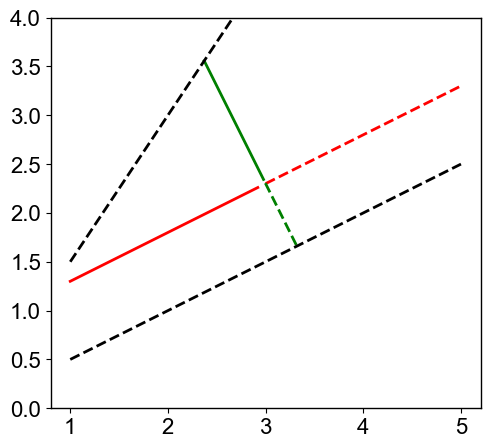

In [22]:

# Set the font family to Arial
plt.rcParams['font.family'] = 'Arial'
plt.rc('font', size=16)

# Create figure with a specific size
f,ax = plt.subplots(figsize=(5, 5))


# Plot lines with different labels
plt.plot(OMEGAL0[:change_pointl0],  MUL0[:change_pointl0], lw=2, label='L1',  color='red')
plt.plot(OMEGAL0[change_pointl0:],  MUL0[change_pointl0:], lw=2, label='L1', linestyle='dashed', color='red')
plt.plot(OMEGAL0perp[:change_pointl0perp],  MUL0perp[:change_pointl0perp], lw=2, label='L1', color='green')
plt.plot(OMEGAL0perp[change_pointl0perp:],  MUL0perp[change_pointl0perp:], lw=2, label='L1', linestyle='dashed', color='green')
plt.plot(OMEGAS1, MUS1, lw=2, linestyle='dashed', color='black', label=f'subband 0')
plt.plot(OMEGAS2, MUS2, lw=2, linestyle='dashed', color='black', label=f'subband 1')

# Set axis limits
plt.ylim(ymax=4, ymin=0)
#plt.xlim(xmin=1)


ax.spines['top'].set_visible(True)
ax.spines['right'].set_visible(True)
ax.spines['left'].set_visible(True)
ax.spines['bottom'].set_visible(True)

# Customize the spines' appearance (optional)
for spine in ax.spines.values():
    spine.set_linewidth(1)  # Set the thickness of the box
    spine.set_color('black')  # Set the color of the box

# Add labels
#plt.xlabel(r'confinement energy, $\mathrm{\Omega}$ (in meV)')
#plt.ylabel(r'chemical potential, $\mathrm{\mu}$ (in meV)')

# Dynamically scale legend font size based on figure size
fig_width, fig_height = f.get_size_inches()
font_size = min(fig_width, fig_height) * 2  # Proportional font size

# Add the legend with the scaled font size
#plt.legend(loc='upper left', prop={'size': font_size}, fontsize=10)

# Set the aspect ratio to 1 using plt.gca() to get the current axes
#plt.gca().set_aspect('equal')
plt.gca().set_aspect(1)

plt.xticks(np.array([1,2,3,4,5]))

#plt.text(3, 0.5,r'subband 0', fontsize=14)
#plt.text(3.5, 4,r'subband 1', fontsize=14)
#plt.text(1.2, 4.2, r'subband 2', fontsize=14)

# Show plot
plt.tight_layout()
plt.show()


In [13]:
NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT_C = 400 
K = 8 

In [14]:
### DATA FOR L0 cubic

Ep_cu_1d = np.empty((NUM,K))

for i in range(NUM):

    Fcu = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGAL0[i], ALPHAT_C, DELTA, MEFF_SC, MEFF_SM, MUL0[i], MUL0[i])
    
    Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu_1d[i,:] = Ecu
    
    if i%5==0:
        print(i)

np.save("cubic_E_L0_omega_from_{}_to_{}_num_{}.npy".format(round(OMEGAL0[0],2), round(OMEGAL0[-1],2), NUM), Ep_cu_1d)


0
5
10
15
20
25
30
35
40
45
50


In [15]:
### DATA FOR L0 perp cubic

Ep_cu_1d = np.empty((NUM,K))

for i in range(NUM):

    Fcu = M.oneD_Minimal_Model(N ,NSM, NSC,MY,AX ,OMEGAL0perp[i], ALPHAT_C, DELTA, MEFF_SC, MEFF_SM, MUL0perp[i], MUL0perp[i])
    
    Hcu = Fcu.H_sys(PHI, so = 'cu', on_both_junc=False)

    Ecu = eigsh(Hcu ,k=K,sigma=0, return_eigenvectors=False)
    
    Ecu = np.sort(Ecu)
    
    Ep_cu_1d[i,:] = Ecu
    
    if i%5==0:
        print(i)

np.save("cubic_E_L0_perp_omega_from_{}_to_{}_num_{}.npy".format(round(OMEGAL0perp[0],2), round(OMEGAL0perp[-1],2), NUM), Ep_cu_1d)


0
5
10
15
20
25
30
35
40
45
50


In [6]:
NUM = 51


### ALL lineas pass through pt (omega, mu) = (3, 2.3)


##SUB1
OMEGAS1 = np.linspace(1,5,NUM)
MUS1 = OMEGAS1/2*np.ones(NUM)

##SUB1
OMEGAS2 = np.linspace(1,5,NUM)
MUS2 = 3*OMEGAS2/2


NSM = 60          # in nm
MY = 7             # no of subbands
AX = 5             # lattice spacing in nm
DELTA = 0.165      # in meV
MEFF_SC = 0.023     # proximitized Ge 
MEFF_SM = 0.023     # Ge
NSC = 500
N = 2*NSC + NSM
PHI = 0.5*np.pi 
ALPHAT_L = 20
ALPHAT_C = 400 
K = 8 


Ecu_L0 = np.load("cubic_E_L0_omega_from_1.0_to_5.0_num_51.npy")
Ecu_L0perp = np.load("cubic_E_L0_perp_omega_from_2.37_to_3.32_num_51.npy")

##finding spin splitting by delta at origin pt (3, 2.3 in this case) for plotting purposes
index_org= np.argmin(np.abs(RL0))
Es_org = (Ecu_L0[index_org,K//2+1]-Ecu_L0[index_org,K//2])/DELTA



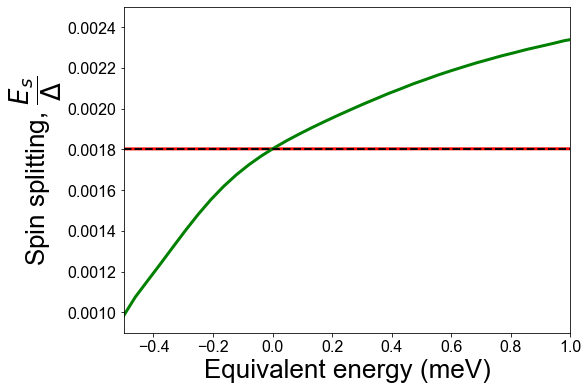

In [10]:
plt.rcParams['font.family'] = 'Arial'

fig, ax = plt.subplots(figsize=(8, 6))  # Define figure size

ax.plot(RL0, (Ecu_L0[:,K//2+1]-Ecu_L0[:,K//2])/DELTA, color='red', lw=3)
ax.plot(RL0perp, (Ecu_L0perp[:,K//2+1]-Ecu_L0perp[:,K//2])/DELTA, color='green', lw=3)
ax.axhline(y=Es_org, color='black', linestyle='--', lw=2)

ax.set_xlabel(r'Equivalent energy (meV)', fontsize=26)  # X-axis label
ax.set_ylabel(r'Spin splitting, $\dfrac{E_s}{\Delta}$', fontsize=26)  # Y-axis label
#ax.grid(True)  # Add grid for better readability
#ax.legend()  # Add legend

ax.set_xlim(xmax=1, xmin=-0.5)
ax.set_ylim(ymax= 0.0025, ymin=0.0009)
#ax.tight_layout()
plt.show()